# Packages

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, GroupKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import SGDClassifier

In [17]:
df = pd.read_csv('../Data/ED_clean.csv')

In [18]:
# Features and target
X = df.drop(columns=['triage_code', 'PatientCode', 'DischargeFromED', 'ChiefComplaint'])
y = df['DischargeFromED']
groups = df['PatientCode']

In [19]:
# Train/test split grouped by patient
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])

# Insights before trying models

Regarding ``DischargeFromED``, patients who are discharged directly from the ED (``DischargeFromED`` = 1), while the second group consists of patients who are transferred to a ward and later discharged from there (``DischargeFromED`` = 0).

Additionally, ``ChiefComplaint`` is described as the reason of consultation declared by the patient, later converted in CIM-10 terms. The risk of a data leakage is low, provided that the coders have merely converted the reason for the consultation into a code. The article does not state whether they were able to draw on the full medical record, including the final diagnosis. Thus, I'll try using models both with and without this variable.

In [20]:
X_train_dp_CC = X_train.drop(columns = ['complaint_3', 'complaint_6', 'complaint_A', 'complaint_B',
       'complaint_C', 'complaint_D', 'complaint_E', 'complaint_F',
       'complaint_G', 'complaint_H', 'complaint_I', 'complaint_J',
       'complaint_K', 'complaint_L', 'complaint_M', 'complaint_N',
       'complaint_O', 'complaint_P', 'complaint_Q', 'complaint_R',
       'complaint_S', 'complaint_T', 'complaint_U', 'complaint_V',
       'complaint_W', 'complaint_X', 'complaint_Y', 'complaint_Z'])

X_test_dp_CC = X_test.drop(columns = ['complaint_3', 'complaint_6', 'complaint_A', 'complaint_B',
       'complaint_C', 'complaint_D', 'complaint_E', 'complaint_F',
       'complaint_G', 'complaint_H', 'complaint_I', 'complaint_J',
       'complaint_K', 'complaint_L', 'complaint_M', 'complaint_N',
       'complaint_O', 'complaint_P', 'complaint_Q', 'complaint_R',
       'complaint_S', 'complaint_T', 'complaint_U', 'complaint_V',
       'complaint_W', 'complaint_X', 'complaint_Y', 'complaint_Z'])

# Models

## Dummy classifier

c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted sa

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     14247
           1       0.50      1.00      0.67     14452

    accuracy                           0.50     28699
   macro avg       0.25      0.50      0.33     28699
weighted avg       0.25      0.50      0.34     28699



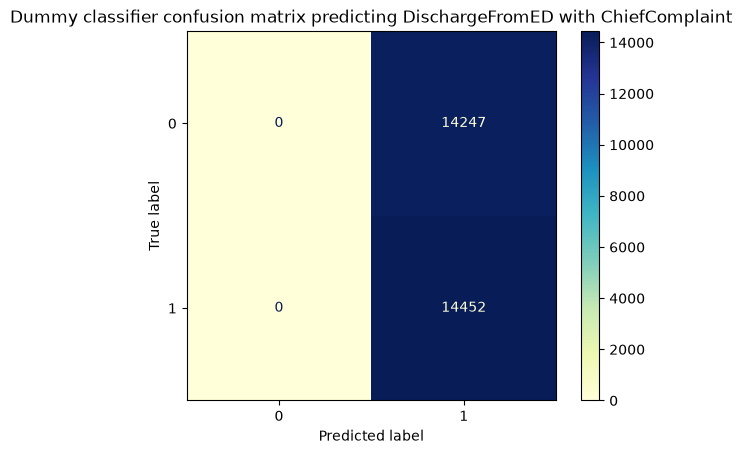

In [21]:
# Model
dc =  DummyClassifier(strategy='most_frequent', random_state=None, constant=None)

# Training
dc.fit(X_train, y_train)

# Prediction
y_pred = dc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
dc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
dc_cm.plot(cmap = 'YlGnBu')
plt.title('Dummy classifier confusion matrix predicting DischargeFromED with ChiefComplaint')
plt.show()

c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\Personal programming\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted sa

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     14247
           1       0.50      1.00      0.67     14452

    accuracy                           0.50     28699
   macro avg       0.25      0.50      0.33     28699
weighted avg       0.25      0.50      0.34     28699



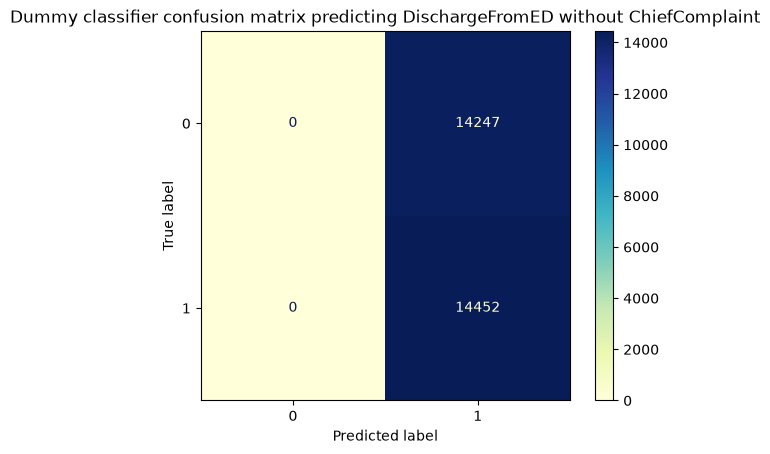

In [22]:
# Model
dc =  DummyClassifier(strategy='most_frequent', random_state=None, constant=None)

# Training
dc.fit(X_train_dp_CC, y_train)

# Prediction
y_pred = dc.predict(X_test_dp_CC)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
dc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
dc_cm.plot(cmap = 'YlGnBu')
plt.title('Dummy classifier confusion matrix predicting DischargeFromED without ChiefComplaint')
plt.show()

## SGD Classifier

              precision    recall  f1-score   support

           0       0.77      0.77      0.77     14247
           1       0.77      0.77      0.77     14452

    accuracy                           0.77     28699
   macro avg       0.77      0.77      0.77     28699
weighted avg       0.77      0.77      0.77     28699



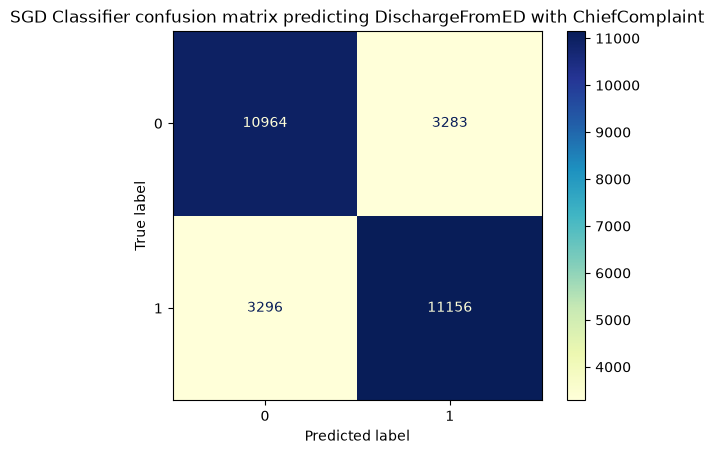

In [23]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train, y_train)

# Prediction
y_pred = sgdc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED with ChiefComplaint')
plt.show()

              precision    recall  f1-score   support

           0       0.72      0.78      0.75     14247
           1       0.77      0.71      0.74     14452

    accuracy                           0.74     28699
   macro avg       0.75      0.74      0.74     28699
weighted avg       0.75      0.74      0.74     28699



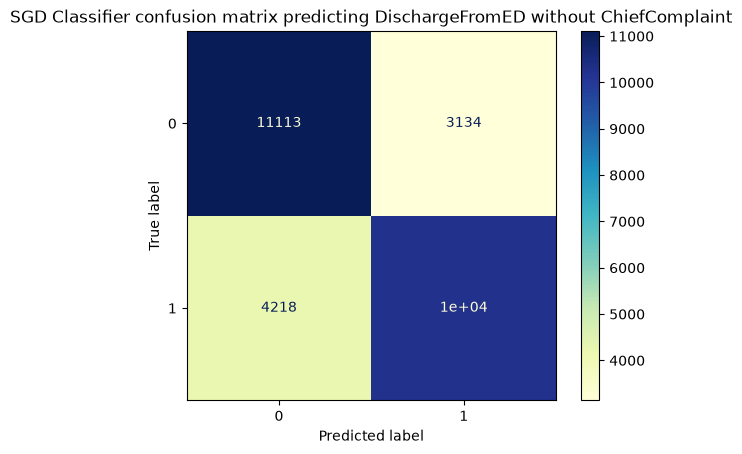

In [24]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(loss="log_loss", max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train_dp_CC, y_train)

# Prediction
y_pred = sgdc.predict(X_test_dp_CC)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED without ChiefComplaint')
plt.show()

As there is only a 4 point difference between the two SGD classifiers, there is little chance of a data leakage. The thing is we don't have access to the CIM-10 terms right away. If needed, we could consider automatically convert the free text to CIM-10. Though, a limit to keep in minde is it is not a guarantee it would be the same as the encoders.

In [ ]:
pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                     SGDClassifier(random_state=42, max_iter=2000, tol=1e-3))

param_grid = {
    "sgdclassifier__alpha": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "sgdclassifier__loss": ["log_loss", "hinge"],
    "sgdclassifier__penalty": ["l2", "l1", "elasticnet"],
}

search = GridSearchCV(pipe, param_grid, cv=GroupKFold(n_splits=5),
                      scoring="roc_auc", n_jobs=-1)

search.fit(X_train, y_train, groups=groups.iloc[train_idx])

print(search.best_params_, search.best_score_)

              precision    recall  f1-score   support

           0       0.76      0.78      0.77     14247
           1       0.78      0.76      0.77     14452

    accuracy                           0.77     28699
   macro avg       0.77      0.77      0.77     28699
weighted avg       0.77      0.77      0.77     28699



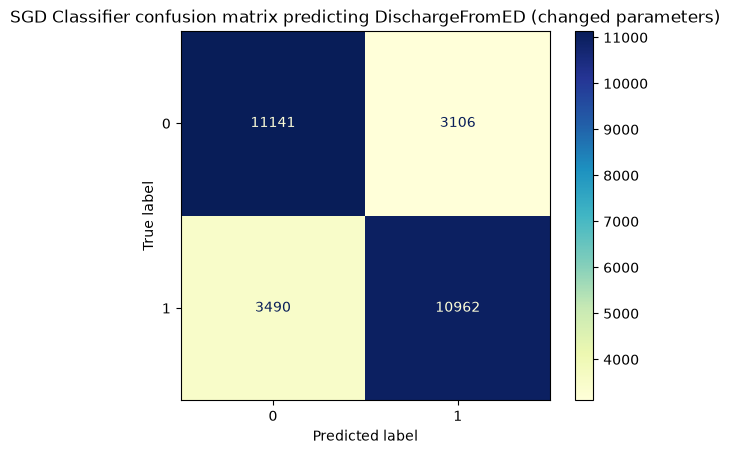

In [ ]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(penalty='l1', alpha=0.001, loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train, y_train)

# Prediction
y_pred = sgdc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED (changed parameters)')
plt.show()

## HistGradientBoostingClassifier

              precision    recall  f1-score   support

           0       0.79      0.86      0.82     14247
           1       0.85      0.78      0.81     14452

    accuracy                           0.82     28699
   macro avg       0.82      0.82      0.82     28699
weighted avg       0.82      0.82      0.82     28699



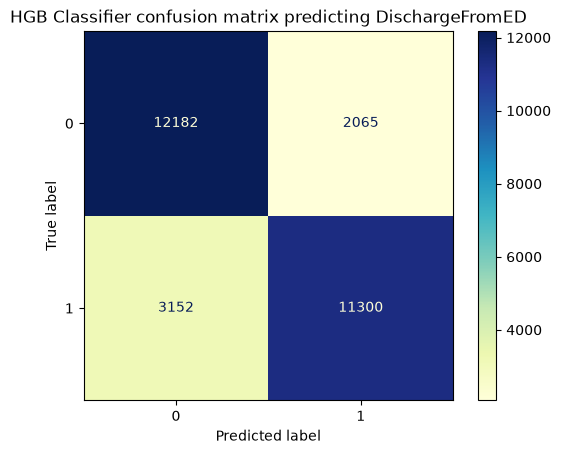

In [ ]:
# Model
hgbc = HistGradientBoostingClassifier()

# Training
hgbc.fit(X_train, y_train)

# Prediction
y_pred = hgbc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
hgbc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
hgbc_cm.plot(cmap = 'YlGnBu')
plt.title('HGB Classifier confusion matrix predicting DischargeFromED')
plt.show()

## XGBoost

[0]	validation_0-logloss:0.59097
[1]	validation_0-logloss:0.53541
[2]	validation_0-logloss:0.50129
[3]	validation_0-logloss:0.47936
[4]	validation_0-logloss:0.46153
[5]	validation_0-logloss:0.45299
[6]	validation_0-logloss:0.44447
[7]	validation_0-logloss:0.43936
[8]	validation_0-logloss:0.43541
[9]	validation_0-logloss:0.43299
[10]	validation_0-logloss:0.42624
[11]	validation_0-logloss:0.42446
[12]	validation_0-logloss:0.42262
[13]	validation_0-logloss:0.41940
[14]	validation_0-logloss:0.41802
[15]	validation_0-logloss:0.41754
[16]	validation_0-logloss:0.41433
[17]	validation_0-logloss:0.41340
[18]	validation_0-logloss:0.41250
[19]	validation_0-logloss:0.41204
[20]	validation_0-logloss:0.41146
[21]	validation_0-logloss:0.41127
[22]	validation_0-logloss:0.40945
[23]	validation_0-logloss:0.40908
[24]	validation_0-logloss:0.40866
[25]	validation_0-logloss:0.40820
[26]	validation_0-logloss:0.40748
[27]	validation_0-logloss:0.40687
[28]	validation_0-logloss:0.40666
[29]	validation_0-loglos

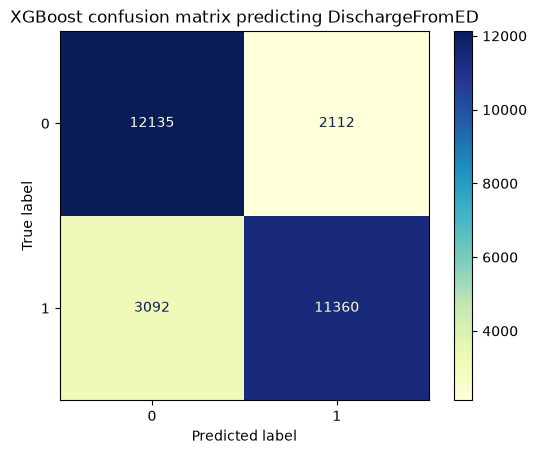

In [ ]:
import xgboost as xgb

# Model
xgb = xgb.XGBClassifier(tree_method="hist", early_stopping_rounds=6)

# Training
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)])

# Prediction
y_pred = xgb.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
xgb_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
xgb_cm.plot(cmap = 'YlGnBu')
plt.title('XGBoost confusion matrix predicting DischargeFromED')
plt.show()